# Notebook 3: Deep Convolutional GAN (DCGAN)
**Assignment-02 | Activity B (CO4): Image Generation** | Prepared by: Manmath (Research & Code Lead)

| | |
|---|---|
| **What to run** | Run all cells top to bottom (no edits needed). |
| **Where output appears** | Progress grids appear every 5 epochs; the final 8x8 grid is saved as `B1_DCGAN.png`. |
| **Expected runtime** | about 4-6 min on T4 GPU |
| **Runtime setting** | Runtime -> Change runtime type -> **T4 GPU**, then **Runtime -> Run all** |

> Ready-made implementation written in Keras, tutorial style. Nothing is trained from scratch beyond a short demo run.

## 1. Idea in brief
Two networks compete: the **Generator** turns random noise into images, and the **Discriminator** tries to tell real images from generated ones.
Each improves by trying to beat the other (adversarial training). DCGAN uses convolutional layers, strided / transposed convolutions instead of pooling, batch normalisation, LeakyReLU in the discriminator and tanh at the generator output.

## 2. Setup

In [1]:
import time
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from tensorflow.keras import layers

SEED = 42
keras.utils.set_random_seed(SEED)
print("TensorFlow:", tf.__version__)
print("GPU:", tf.config.list_physical_devices("GPU") or "none (switch runtime to T4 GPU)")

TensorFlow: 2.21.0
GPU: [PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


## 3. Load data (scaled to [-1, 1] to match the generator's tanh output)

In [2]:
(x_train, _), (_, _) = keras.datasets.fashion_mnist.load_data()
x_train = (np.expand_dims(x_train.astype("float32"), -1) - 127.5) / 127.5
BATCH_SIZE, NOISE_DIM = 128, 100
dataset = tf.data.Dataset.from_tensor_slices(x_train).shuffle(60000, seed=SEED).batch(BATCH_SIZE, drop_remainder=True).prefetch(2)
print(x_train.shape)

29515/29515 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
26421880/26421880 ━━━━━━━━━━━━━━━━━━━━ 3s 0us/step
5148/5148 ━━━━━━━━━━━━━━━━━━━━ 0s 0us/step
4422102/4422102 ━━━━━━━━━━━━━━━━━━━━ 1s 0us/step
(60000, 28, 28, 1)


## 4. Build the Generator and Discriminator

In [3]:
generator = keras.Sequential([
    layers.Input((NOISE_DIM,)),
    layers.Dense(7 * 7 * 256, use_bias=False),
    layers.BatchNormalization(), layers.LeakyReLU(0.2),
    layers.Reshape((7, 7, 256)),
    layers.Conv2DTranspose(128, 5, strides=1, padding="same", use_bias=False),
    layers.BatchNormalization(), layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(64, 5, strides=2, padding="same", use_bias=False),     # 14x14
    layers.BatchNormalization(), layers.LeakyReLU(0.2),
    layers.Conv2DTranspose(1, 5, strides=2, padding="same", activation="tanh"),   # 28x28
], name="generator")

discriminator = keras.Sequential([
    layers.Input((28, 28, 1)),
    layers.Conv2D(64, 5, strides=2, padding="same"), layers.LeakyReLU(0.2), layers.Dropout(0.3),
    layers.Conv2D(128, 5, strides=2, padding="same"), layers.LeakyReLU(0.2), layers.Dropout(0.3),
    layers.Flatten(),
    layers.Dense(1),   # logit: real vs fake
], name="discriminator")

generator.summary()

Model: "generator"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 12544)          │     1,254,400 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization             │ (None, 12544)          │        50,176 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu (LeakyReLU)         │ (None, 12544)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ reshape (Reshape)               │ (None, 7, 7, 256)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose                │ (None, 7, 7, 128)      │       819,200 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_1           │ (None, 7, 7, 128)      │           512 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_1 (LeakyReLU)       │ (None, 7, 7, 128)      │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_1              │ (None, 14, 14, 64)     │       204,800 │
│ (Conv2DTranspose)               │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ batch_normalization_2           │ (None, 14, 14, 64)     │           256 │
│ (BatchNormalization)            │                        │               │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ leaky_re_lu_2 (LeakyReLU)       │ (None, 14, 14, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_transpose_2              │ (None, 28, 28, 1)      │         1,601 │
│ (Conv2DTranspose)               │                        │               │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 2,330,945 (8.89 MB)

 Trainable params: 2,305,473 (8.79 MB)

 Non-trainable params: 25,472 (99.50 KB)

## 5. Training loop (custom `train_step`, as in the Keras / TensorFlow DCGAN tutorials)

In [4]:
bce = keras.losses.BinaryCrossentropy(from_logits=True)
g_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)
d_opt = keras.optimizers.Adam(2e-4, beta_1=0.5)

@tf.function
def train_step(real_images):
    noise = tf.random.normal([BATCH_SIZE, NOISE_DIM])
    with tf.GradientTape() as g_tape, tf.GradientTape() as d_tape:
        fake_images = generator(noise, training=True)
        real_out = discriminator(real_images, training=True)
        fake_out = discriminator(fake_images, training=True)
        g_loss = bce(tf.ones_like(fake_out), fake_out)                       # generator wants "real"
        d_loss = bce(tf.ones_like(real_out), real_out) + bce(tf.zeros_like(fake_out), fake_out)
    g_opt.apply_gradients(zip(g_tape.gradient(g_loss, generator.trainable_variables), generator.trainable_variables))
    d_opt.apply_gradients(zip(d_tape.gradient(d_loss, discriminator.trainable_variables), discriminator.trainable_variables))
    return g_loss, d_loss

fixed_noise = tf.random.normal([64, NOISE_DIM], seed=SEED)   # same noise each time -> progress is comparable

def show_grid(title, fname=None):
    imgs = generator(fixed_noise, training=False).numpy() * 0.5 + 0.5
    fig, axes = plt.subplots(8, 8, figsize=(7, 7))
    for ax, im in zip(axes.ravel(), imgs):
        ax.imshow(im.squeeze(), cmap="gray"); ax.axis("off")
    fig.suptitle(title)
    if fname: plt.savefig(fname, dpi=200, bbox_inches="tight")
    plt.show()

epoch 01  G loss 0.696  D loss 1.352
epoch 02  G loss 0.783  D loss 1.283
epoch 03  G loss 0.920  D loss 1.169
epoch 04  G loss 0.833  D loss 1.274
epoch 05  G loss 0.796  D loss 1.296


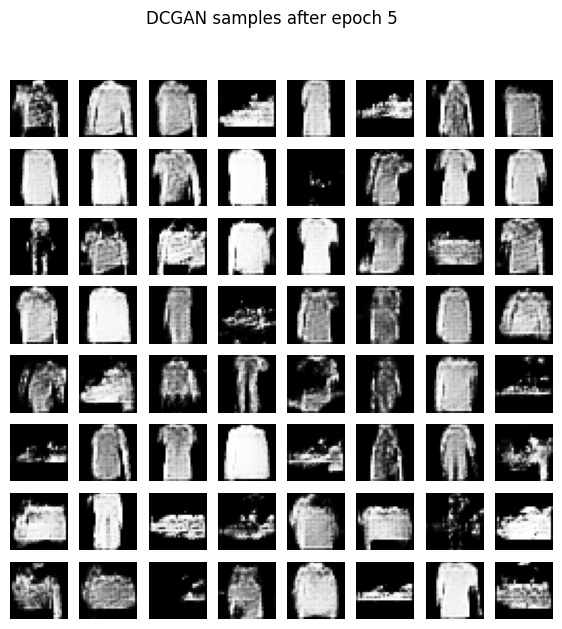

epoch 06  G loss 0.798  D loss 1.292
epoch 07  G loss 0.793  D loss 1.295
epoch 08  G loss 0.782  D loss 1.311
epoch 09  G loss 0.781  D loss 1.316
epoch 10  G loss 0.771  D loss 1.323


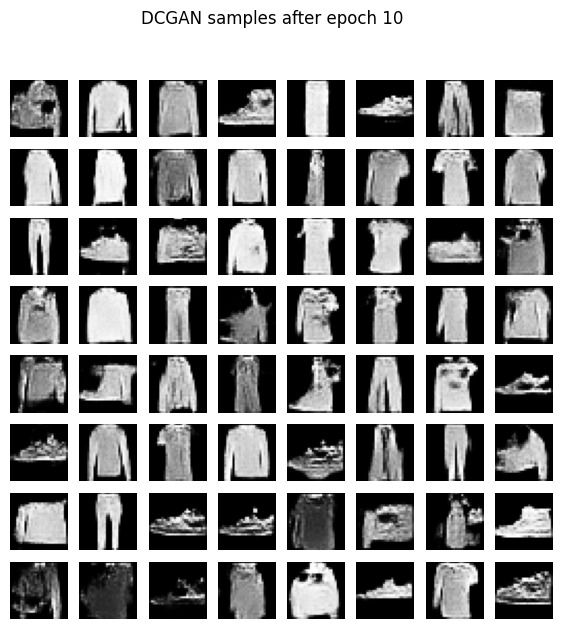

epoch 11  G loss 0.770  D loss 1.325
epoch 12  G loss 0.766  D loss 1.325
epoch 13  G loss 0.776  D loss 1.320
epoch 14  G loss 0.770  D loss 1.322
epoch 15  G loss 0.772  D loss 1.324


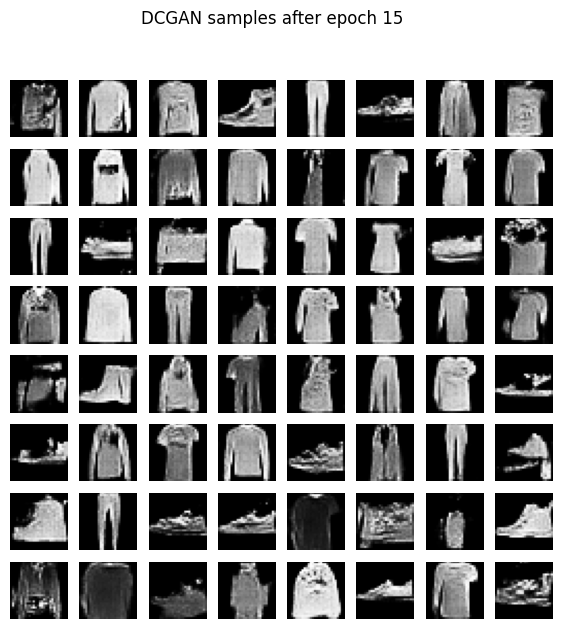

epoch 16  G loss 0.774  D loss 1.323
epoch 17  G loss 0.775  D loss 1.323
epoch 18  G loss 0.774  D loss 1.324
epoch 19  G loss 0.774  D loss 1.324
epoch 20  G loss 0.772  D loss 1.325


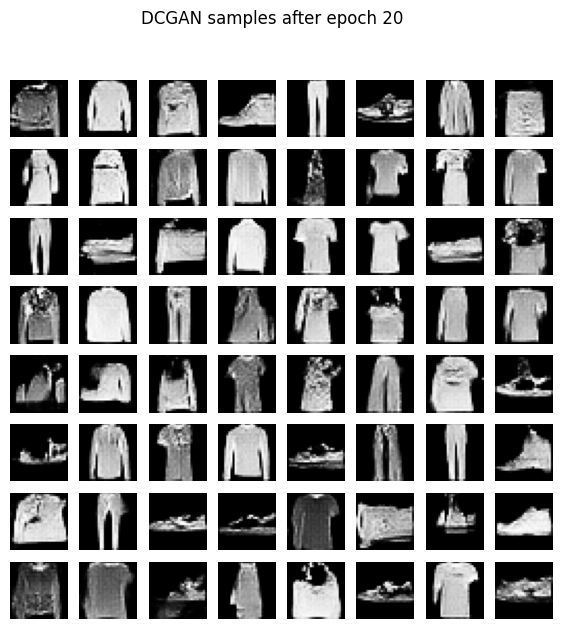

Training time: 326.7 s


In [5]:
EPOCHS = 20
g_hist, d_hist = [], []
start = time.time()
for epoch in range(1, EPOCHS + 1):
    gl, dl = [], []
    for batch in dataset:
        g, d = train_step(batch); gl.append(float(g)); dl.append(float(d))
    g_hist.append(np.mean(gl)); d_hist.append(np.mean(dl))
    print(f"epoch {epoch:02d}  G loss {g_hist[-1]:.3f}  D loss {d_hist[-1]:.3f}")
    if epoch % 5 == 0:
        show_grid(f"DCGAN samples after epoch {epoch}")
train_time = time.time() - start
print(f"Training time: {train_time:.1f} s")

## 6. Final generated grid (screenshot this cell)

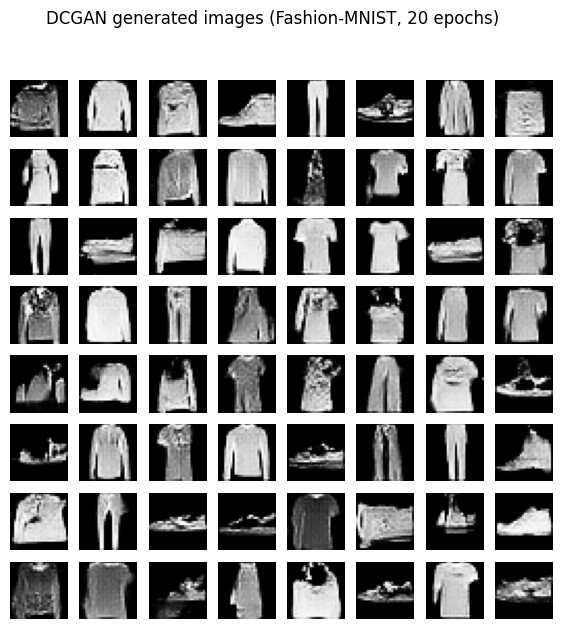

In [6]:
show_grid("DCGAN generated images (Fashion-MNIST, %d epochs)" % EPOCHS, "B1_DCGAN.png")

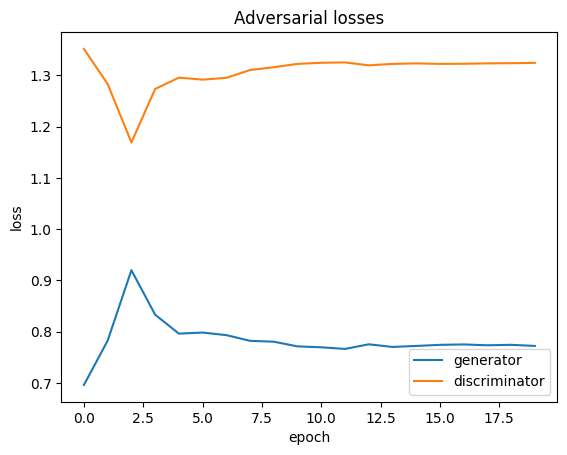

In [7]:
plt.plot(g_hist, label="generator"); plt.plot(d_hist, label="discriminator")
plt.xlabel("epoch"); plt.ylabel("loss"); plt.title("Adversarial losses"); plt.legend(); plt.show()

## 7. Observation notes (copy into the Observation Table)
- Sharpness / realism: ______  | Artifacts or distorted samples: ______
- Variety (any repeated items = possible mode collapse?): ______
- Runtime: see "Training time" above.